# ACTIVIDAD - Método K-Medias

In [1]:
import pandas as pd
import matplotlib.pyplot as mp
import seaborn as sb
import os
import warnings
warnings.filterwarnings("ignore")

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn import decomposition

# cargamos nuestros datos Iris.csv 
os.chdir("/Users/lleid/Downloads")    #"C:\Users\lleid\Downloads\iris.csv"
dataset = pd.read_csv("Iris.csv")
dataset.head()

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [2]:
# Seleccionamos únicamente las columnas numéricas originales (sépalo y pétalo), sin transformar
fields = dataset.iloc[:, [0,1,2,3]].values
print(fields)

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

In [3]:
# Determinamos el número óptimo de clusters con método del codo de Jambú
wcss = []
for index in range(1,11):
    kmeans = KMeans(n_clusters = index, init = "k-means++", random_state = 2)
    kmeans.fit(fields)

    wcss.append(kmeans.inertia_)

Text(0, 0.5, 'WCSS')

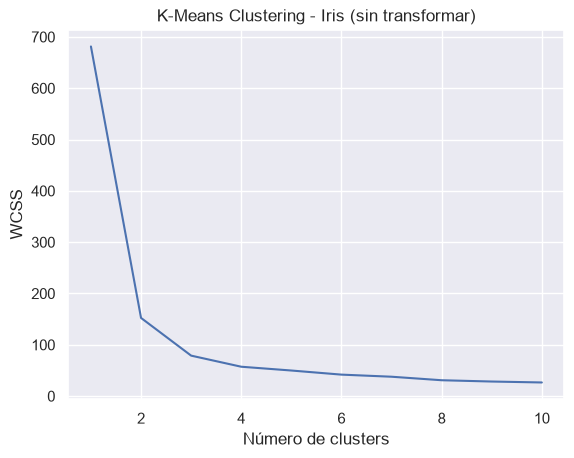

In [4]:
# Graficacion del "Codo de Jambu" 
sb.set()
mp.plot(range(1,11), wcss)
mp.title("K-Means Clustering - Iris (sin transformar)")
mp.xlabel("Número de clusters")
mp.ylabel("WCSS")  #Weighted cluster sum of squares

In [5]:
# Determinamos el número óptimo de clusters: indicador de Silhouette
for j in range(2,12):  #el minimo para este indicador es de 2
    kmeans = KMeans(n_clusters = j, random_state = 42)
    kmeans.fit_predict(fields)
    score = silhouette_score(fields, kmeans.labels_, metric='euclidean')
    print("Score Silhouette;", "k = ", j, ":", score)

Score Silhouette; k =  2 : 0.6810461692117465
Score Silhouette; k =  3 : 0.5511916046195926
Score Silhouette; k =  4 : 0.4976433179321929
Score Silhouette; k =  5 : 0.4930804067193527
Score Silhouette; k =  6 : 0.3678464984712253
Score Silhouette; k =  7 : 0.35429788771988574
Score Silhouette; k =  8 : 0.3446797218056204
Score Silhouette; k =  9 : 0.31558878533897844
Score Silhouette; k =  10 : 0.30141437453251513
Score Silhouette; k =  11 : 0.2687356216412034


In [15]:
# Aplicamos K-Medias con el número óptimo de clusters guiandonos en el codo de jambu ya que silhouette no coincidió
kmeans = KMeans(n_clusters = 3, init = "k-means++", random_state = 42)
cluster_values = kmeans.fit_predict(fields)
print(cluster_values)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]


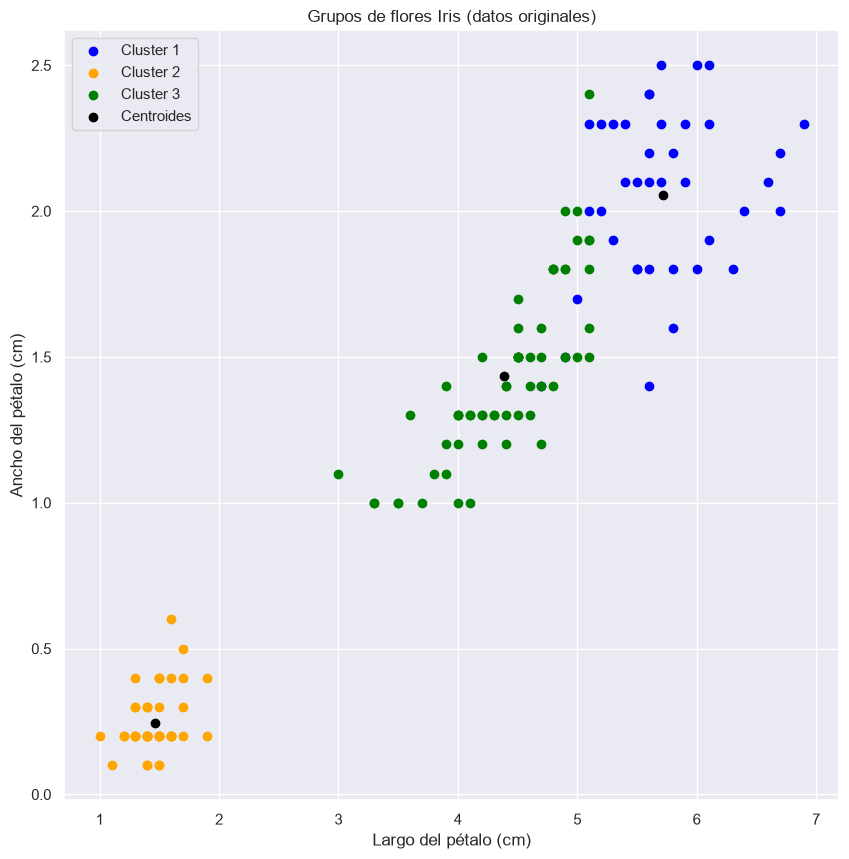

In [17]:
# Graficamos los grupos obtenidos SIN transformación, usando dos variables originales
# Columna 2 = petal_length, Columna 3 = petal_width
mp.figure(figsize=(10,10))
mp.scatter(fields[cluster_values==0,2], fields[cluster_values==0,3], c = 'blue',   label = 'Cluster 1')
mp.scatter(fields[cluster_values==1,2], fields[cluster_values==1,3], c = 'orange', label = 'Cluster 2')
mp.scatter(fields[cluster_values==2,2], fields[cluster_values==2,3], c = 'green',  label = 'Cluster 3')

mp.scatter(kmeans.cluster_centers_[:,2], kmeans.cluster_centers_[:,3], c = 'black', label = 'Centroides')

mp.title("Grupos de flores Iris (datos originales)")
mp.xlabel("Largo del pétalo (cm)")
mp.ylabel("Ancho del pétalo (cm)")
mp.legend()

In [7]:
# Transformamos las 4 columnas numéricas originales en 2 componentes principales
pca = decomposition.PCA(n_components=2)
pca.fit(fields)
fields_pca = pca.transform(fields)
fields_pca

array([[-2.68412563,  0.31939725],
       [-2.71414169, -0.17700123],
       [-2.88899057, -0.14494943],
       [-2.74534286, -0.31829898],
       [-2.72871654,  0.32675451],
       [-2.28085963,  0.74133045],
       [-2.82053775, -0.08946138],
       [-2.62614497,  0.16338496],
       [-2.88638273, -0.57831175],
       [-2.6727558 , -0.11377425],
       [-2.50694709,  0.6450689 ],
       [-2.61275523,  0.01472994],
       [-2.78610927, -0.235112  ],
       [-3.22380374, -0.51139459],
       [-2.64475039,  1.17876464],
       [-2.38603903,  1.33806233],
       [-2.62352788,  0.81067951],
       [-2.64829671,  0.31184914],
       [-2.19982032,  0.87283904],
       [-2.5879864 ,  0.51356031],
       [-2.31025622,  0.39134594],
       [-2.54370523,  0.43299606],
       [-3.21593942,  0.13346807],
       [-2.30273318,  0.09870885],
       [-2.35575405, -0.03728186],
       [-2.50666891, -0.14601688],
       [-2.46882007,  0.13095149],
       [-2.56231991,  0.36771886],
       [-2.63953472,

In [9]:
# Repetimos el método del codo ahora sobre los datos transformados por PCA
wcss_pca = []
for index in range(1,11):
    kmeans = KMeans(n_clusters = index, init = "k-means++", random_state = 2)
    kmeans.fit(fields_pca)

    wcss_pca.append(kmeans.inertia_)

Text(0, 0.5, 'WCSS')

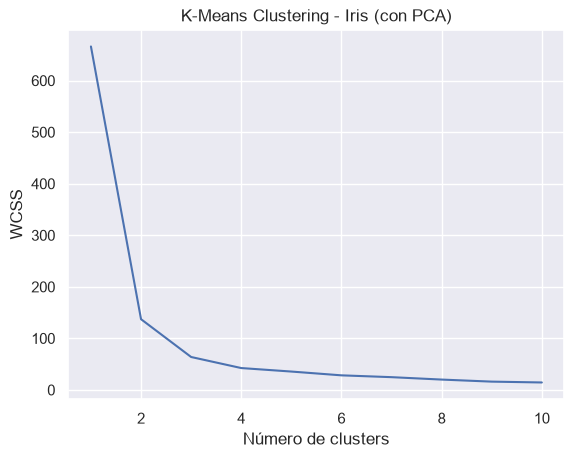

In [10]:
# Graficacion del "Codo de Jambu" con datos transformados por PCA
sb.set()
mp.plot(range(1,11), wcss_pca)
mp.title("K-Means Clustering - Iris (con PCA)")
mp.xlabel("Número de clusters")
mp.ylabel("WCSS")  #Weighted cluster sum of squares

In [11]:
# Repetimos el indicador de Silhouette sobre los datos transformados por PCA
for j in range(2,12):
    kmeans = KMeans(n_clusters = j, random_state = 42)
    kmeans.fit_predict(fields_pca)
    score = silhouette_score(fields_pca, kmeans.labels_, metric='euclidean')
    print("Score Silhouette;", "k = ", j, ":", score)

Score Silhouette; k =  2 : 0.7056703225102109
Score Silhouette; k =  3 : 0.597676421954799
Score Silhouette; k =  4 : 0.5577409232246783
Score Silhouette; k =  5 : 0.5100407194899201
Score Silhouette; k =  6 : 0.40319738737442673
Score Silhouette; k =  7 : 0.3868263997713608
Score Silhouette; k =  8 : 0.44076033249654034
Score Silhouette; k =  9 : 0.4020143876366362
Score Silhouette; k =  10 : 0.4158865801753246
Score Silhouette; k =  11 : 0.39943255193052346


In [12]:
# Aplicamos K-Medias con el número óptimo de clusters sobre los datos con PCA
kmeans_pca = KMeans(n_clusters = 3, init = "k-means++", random_state = 42)
cluster_values_pca = kmeans_pca.fit_predict(fields_pca)
print(cluster_values_pca)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]


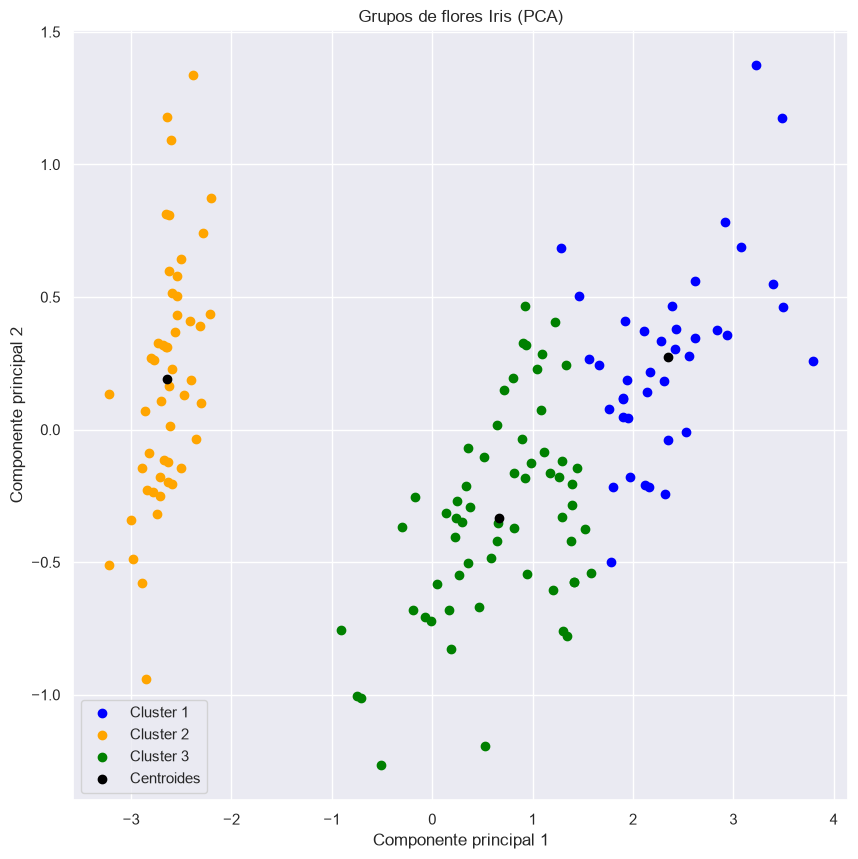

In [13]:
# Graficamos los grupos obtenidos considerando las dos componentes resultantes del PCA
mp.figure(figsize=(10,10))
mp.scatter(fields_pca[cluster_values_pca==0,0], fields_pca[cluster_values_pca==0,1], c = 'blue',   label = 'Cluster 1')
mp.scatter(fields_pca[cluster_values_pca==1,0], fields_pca[cluster_values_pca==1,1], c = 'orange', label = 'Cluster 2')
mp.scatter(fields_pca[cluster_values_pca==2,0], fields_pca[cluster_values_pca==2,1], c = 'green',  label = 'Cluster 3')

mp.scatter(kmeans_pca.cluster_centers_[:,0], kmeans_pca.cluster_centers_[:,1], c = 'black', label = 'Centroides')

mp.title("Grupos de flores Iris (PCA)")
mp.xlabel("Componente principal 1")
mp.ylabel("Componente principal 2")
mp.legend()

# ¿Se obtuvieron los mismos resultados de agrupamiento?

# Ventaja práctica de aplicar PCA antes de k-medias: